# OvaScope — Parasite Egg Image Classification Pipeline

## Section 1 — Project introduction

**OvaScope** is an end-to-end machine-learning system that classifies microscope images of
human intestinal parasite eggs into **11 categories**.

**Why it matters.** Intestinal parasites are diagnosed by a trained technician who looks for eggs in
stool samples under a microscope. The work is slow, needs expertise, and gets tiring with large
sample numbers. An automatic classifier could help with triage and training. In this project it is a
research prototype only.

**Dataset.** [Chula-ParasiteEgg-11](https://zenodo.org/records/15866298) (Chulalongkorn University and
collaborators; ICIP 2022 challenge). It has 11,000 training photos and 2,200 test photos from several
microscopes, cameras and smartphones, with COCO bounding boxes around every egg.

**What the model does.** It takes an image **already cropped around one egg** and outputs a probability
for each of the 11 classes.

**What it does not do.** It does **not** find or count eggs in a full microscope photo (that would need
object detection). It is **not** a clinically validated diagnostic tool, and its confidence is a model
score, not a guarantee.

**Outputs of this notebook**
* verified single-egg crop dataset (rebuilt here from the official files)
* exploratory analysis of three image features
* a baseline CNN and a MobileNetV2 transfer-learning model, trained and compared on validation data
* final held-out test evaluation (accuracy, loss, macro precision / recall / F1, confusion matrix)
* saved `.keras` and load-tested `.h5` model, class mapping, metadata
* `ovascope_training_results.zip` with all results

## Section 2 — Learning objectives and workflow

```
Official data (Zenodo) ─► Crops (one egg each) ─► Verification ─► Exploration (EDA)
        ─► Preprocessing (resize, augment, batch) ─► Training (baseline CNN, MobileNetV2)
        ─► Validation-based model selection ─► Final test evaluation ─► Saving ─► Prediction
        ─► Retraining readiness ─► Export
```

Rules followed throughout:
1. **Three separate sets.** *train* fits weights. *validation* drives early stopping and model selection.
   *test* is used **once**, at the end, on the selected model only.
2. **One preprocessing implementation.** Every step calls functions from `src/`. The API and the
   retraining job use the same functions, so training and serving cannot disagree.
3. **Only real results.** Every number shown below is produced by the cells in this notebook.

## Section 3 — Environment setup

The notebook runs in three environments:

| Environment | Project code | Data | Outputs |
|---|---|---|---|
| Local Jupyter | the repository (auto-detected) | `data/processed` (crops) and `data/raw` (official zips) | the repository (`models/`, `artifacts/`) |
| Google Colab | clone, or upload/unzip the project, or Google Drive | crops ZIP uploaded or on Drive | `/content/ovascope_outputs` (or Drive) |
| Kaggle | project attached as an input dataset | crops ZIP / folder attached as input | `/kaggle/working/ovascope_outputs` |

The next cell holds **all user settings**. `ENVIRONMENT = "auto"` detects the platform; set it by hand
if detection is wrong. No path is hard-coded to one person's home folder.

In [1]:
import os
import platform
import sys
from pathlib import Path

# ---------------- Settings you may change ----------------
ENVIRONMENT = "auto"       # "auto" | "local" | "colab" | "kaggle"
PROJECT_DIR = None         # folder containing src/ and configs/ (None = auto-detect)
DATA_DIR = None            # folder with crops/, manifest.csv, class_map.json (None = auto-detect)
RAW_DATA_DIR = None        # folder with the official Zenodo files (only needed to rebuild crops)
OUTPUT_DIR = None          # writable folder for models and results (None = environment default)
REBUILD_CROPS = True       # rebuild crops from the official archives and prove they are identical
QUICK_RUN = False          # True = 1-2 epochs per stage, only to check that everything runs
USE_GOOGLE_DRIVE = False   # Colab: mount Google Drive (data and/or results live there)
PROJECT_REPO_URL = ""      # optional: git URL to clone the project code if it is not present
# ----------------------------------------------------------


def detect_environment():
    try:
        import google.colab  # noqa: F401
        return "colab"
    except ImportError:
        pass
    if os.environ.get("KAGGLE_KERNEL_RUN_TYPE") or Path("/kaggle/working").exists():
        return "kaggle"
    return "local"


ENV = detect_environment() if ENVIRONMENT == "auto" else ENVIRONMENT
print("Environment:", ENV)
print("Python:", sys.version.split()[0], "|", platform.platform())
print("Working directory:", Path.cwd())

Environment: local
Python: 3.12.16 | Linux-7.0.0-43-generic-x86_64-with-glibc2.43
Working directory: /home/maurice/Documents/ML_Pipeline/ovascope-MLOP/notebook


In [2]:
if ENV == "colab" and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")


def looks_like_project(folder: Path) -> bool:
    return (folder / "src" / "preprocessing.py").exists() and (folder / "configs" / "config.yaml").exists()


def find_project_dir():
    if PROJECT_DIR:
        return Path(PROJECT_DIR)
    candidates = [Path.cwd(), Path.cwd().parent]
    if ENV == "colab":
        candidates += [Path("/content/ovascope-MLOP"), Path("/content/drive/MyDrive/ovascope-MLOP")]
    if ENV == "kaggle":
        candidates += sorted(Path("/kaggle/input").glob("*")) + sorted(Path("/kaggle/input").glob("*/*"))
        candidates += [Path("/kaggle/working/ovascope-MLOP")]
    for folder in candidates:
        if looks_like_project(folder):
            return folder.resolve()
    if PROJECT_REPO_URL:
        target = Path("/content" if ENV == "colab" else "/kaggle/working" if ENV == "kaggle" else ".") / "ovascope-MLOP"
        os.system(f"git clone --depth 1 {PROJECT_REPO_URL} {target}")
        if looks_like_project(target):
            return target.resolve()
    raise FileNotFoundError(
        "Project code (src/, configs/) not found. Local: start Jupyter inside the repository. "
        "Colab: upload and unzip the project to /content/ovascope-MLOP (or set PROJECT_REPO_URL). "
        "Kaggle: attach the project as an input dataset.")


PROJECT = find_project_dir()
sys.path.insert(0, str(PROJECT))
print("Project directory:", PROJECT)

Project directory: /home/maurice/Documents/ML_Pipeline/ovascope-MLOP


## Section 4 — Dependency management

Libraries used: **TensorFlow/Keras** (models), **NumPy / pandas** (arrays, tables), **Pillow** (image
files), **scikit-learn** (metrics), **Matplotlib** (plots), **PyYAML** (configuration).
The next cell installs a package **only if it cannot be imported**. Colab and Kaggle already ship
TensorFlow, so normally nothing is installed there. Exact tested versions are listed in
`requirements.txt`.

In [3]:
import importlib
import subprocess

REQUIRED = {"tensorflow": "tensorflow", "numpy": "numpy", "pandas": "pandas", "PIL": "pillow",
            "sklearn": "scikit-learn", "matplotlib": "matplotlib", "yaml": "pyyaml"}
for module, package in REQUIRED.items():
    try:
        importlib.import_module(module)
    except ImportError:
        print(f"Installing missing package: {package}")
        result = subprocess.run([sys.executable, "-m", "pip", "install", "-q", package])
        if result.returncode != 0:
            raise RuntimeError(f"Could not install {package}; install it manually and restart the kernel.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

from src.train import configure_gpu, describe_environment

configure_gpu()
environment_info = describe_environment()
pd.Series(environment_info).to_frame("value")

,value
date_utc,2026-11-23T11:12:14+00:00
python,3.12.16
platform,Linux-7.0.0-43-generic-x86_64-with-glibc2.43
tensorflow,2.21.0
keras,3.15.1
numpy,2.5.5
pandas,3.1.1
scikit_learn,1.9.1
pillow,13.0.0
cpu_count,16


If `accelerator` shows **CPU**, everything still works, but training is much slower. Use
`QUICK_RUN = True` to check the pipeline first. On Colab choose *Runtime → Change runtime type → GPU*;
on Kaggle switch the accelerator on in the notebook settings.

## Section 5 — Dataset location and configuration

All settings (image size, epochs, learning rates, split fractions…) live in **`configs/config.yaml`**, and
`src.config.load_config()` reads them. Paths can be redirected with environment variables, which is how
the same code runs on Colab and Kaggle:

* **Local**: crops in `data/processed`, official archives in `data/raw`.
* **Colab**: upload `chula_parasite_egg11_crops.zip` (or keep it on Drive). The next cell finds and unzips it.
* **Kaggle**: attach the crops ZIP or folder as an input dataset (read-only, under `/kaggle/input`); outputs go to
  `/kaggle/working`.

The large dataset is never downloaded again if it is already present.

In [4]:
import zipfile

if OUTPUT_DIR is None:
    OUTPUT_DIR = {"local": PROJECT,
                  "colab": Path("/content/drive/MyDrive/ovascope_outputs") if USE_GOOGLE_DRIVE else Path("/content/ovascope_outputs"),
                  "kaggle": Path("/kaggle/working/ovascope_outputs")}[ENV]
OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def find_data_dir():
    if DATA_DIR:
        return Path(DATA_DIR)
    if ENV == "local" and (PROJECT / "data" / "processed" / "manifest.csv").exists():
        return PROJECT / "data" / "processed"
    search_roots = {"colab": [Path("/content"), Path("/content/drive/MyDrive")],
                    "kaggle": [Path("/kaggle/input")], "local": [PROJECT / "data"]}[ENV]
    for root in search_roots:
        for manifest in root.glob("**/manifest.csv"):
            if (manifest.parent / "crops").is_dir():
                return manifest.parent
    for root in search_roots:   # a crops ZIP: extract it to the writable output folder
        for archive in root.glob("**/chula_parasite_egg11_crops.zip"):
            target = OUTPUT_DIR / "data" / "processed"
            if not (target / "manifest.csv").exists():
                print("Extracting", archive)
                zipfile.ZipFile(archive).extractall(target)
            return target
    return OUTPUT_DIR / "data" / "processed"   # empty: crops will be built from the raw archives


def find_raw_dir():
    if RAW_DATA_DIR:
        return Path(RAW_DATA_DIR)
    roots = {"local": [PROJECT / "data" / "raw"], "colab": [Path("/content"), Path("/content/drive/MyDrive")],
             "kaggle": [Path("/kaggle/input")]}[ENV]
    for root in roots:
        for archive in root.glob("**/Chula-ParasiteEgg-11.zip"):
            return archive.parent
    return None


PROCESSED_DIR = find_data_dir()
RAW_DIR = find_raw_dir()
os.environ["OVASCOPE_PROCESSED_DIR"] = str(PROCESSED_DIR)
os.environ["OVASCOPE_MODELS_DIR"] = str(OUTPUT_DIR / "models")
os.environ["OVASCOPE_ARTIFACTS_DIR"] = str(OUTPUT_DIR / "artifacts")
os.environ["OVASCOPE_DB"] = str(OUTPUT_DIR / "db" / "ovascope.db")
if RAW_DIR:
    os.environ["OVASCOPE_RAW_DIR"] = str(RAW_DIR)
    if ENV != "local":
        os.environ["OVASCOPE_EXTRACTED_DIR"] = str(OUTPUT_DIR / "data" / "extracted")

from src.config import load_config

cfg = load_config()
if QUICK_RUN:
    cfg["training"]["baseline"]["epochs"] = 2
    cfg["training"]["transfer"].update(head_epochs=1, fine_tune_epochs=1)
SEED = cfg["project"]["random_seed"]
IMAGE_SIZE = cfg["training"]["image_size"]
BATCH_SIZE = cfg["training"]["batch_size"]
PLOTS = cfg["paths"]["artifacts_dir"] / "plots"
METRICS = cfg["paths"]["artifacts_dir"] / "metrics"
PLOTS.mkdir(parents=True, exist_ok=True)
METRICS.mkdir(parents=True, exist_ok=True)

pd.DataFrame({"setting": ["environment", "processed data", "raw archives", "outputs", "image size", "batch size",
                          "random seed", "quick run"],
              "value": [ENV, PROCESSED_DIR, RAW_DIR, OUTPUT_DIR, IMAGE_SIZE, BATCH_SIZE, SEED, QUICK_RUN]})

,setting,value
0,environment,local
1,processed data,/home/maurice/Documents/ML_Pipeline/ovascope-M...
2,raw archives,/home/maurice/Documents/ML_Pipeline/ovascope-M...
3,outputs,/home/maurice/Documents/ML_Pipeline/ovascope-MLOP
4,image size,224
5,batch size,32
6,random seed,42
7,quick run,False


### Rebuilding the crop dataset from the official files

The official dataset was made for **object detection**: each photo comes with boxes around its eggs.
Our task is **classification**, so `src.preprocessing.build_crop_dataset` turns every box into its own image:

1. **Verify** the downloaded archives against the MD5 checksums published on Zenodo.
2. **Pad** each box by 10% per side, so the whole shell plus a little background is kept.
3. **Make it square** around its centre. Later resizing to 224×224 then cannot stretch the egg.
4. **Clamp** the square inside the photo (no artificial padding pixels).
5. **Split** the official training photos 85/15 into train/validation. The split is stratified by class and
   **grouped by photo**, so eggs from one photo never land in different splits. The official test set
   (labelled by `test_labels_200.json`) is the held-out test set.
6. Write `manifest.csv` (one row per crop, with its source photo and box) and `class_map.json`.

When `REBUILD_CROPS = True` and the official files are available, the next cell first fingerprints
(MD5) every existing crop. It then rebuilds everything and checks that the result is **byte-for-byte identical**.
This shows that the crop dataset is fully reproducible from the official source.

In [5]:
import hashlib
import time

from src.preprocessing import prepare_dataset


def fingerprint_crops(processed_dir: Path) -> dict:
    return {str(p.relative_to(processed_dir)): hashlib.md5(p.read_bytes()).hexdigest()
            for p in sorted((processed_dir / "crops").rglob("*.jpg"))}


raw_available = bool(RAW_DIR) and (Path(RAW_DIR) / "Chula-ParasiteEgg-11.zip").exists()
if REBUILD_CROPS and raw_available:
    before = fingerprint_crops(PROCESSED_DIR) if (PROCESSED_DIR / "crops").exists() else {}
    start = time.time()
    report = prepare_dataset(cfg, rebuild=True, workers=os.cpu_count() or 2)
    print(f"Rebuilt {report['total_crops']} crops in {time.time() - start:.0f} s")
    after = fingerprint_crops(PROCESSED_DIR)
    if before:
        same = sum(before.get(k) == v for k, v in after.items())
        print(f"Previously existing crops: {len(before)} | rebuilt: {len(after)} | byte-identical: {same}")
        print("Reproducible:", same == len(before) == len(after))
else:
    if REBUILD_CROPS:
        print("Official archives not available here: reusing the prepared crops instead of rebuilding.")
    report = prepare_dataset(cfg, rebuild=False)

Verifying the official files against the Zenodo MD5 checksums...


Archive check: {'Chula-ParasiteEgg-11.zip': 'ok', 'Chula-ParasiteEgg-11_test.zip': 'ok', 'test_labels_200.json': 'ok'}


Building crops (one image per annotated egg)...


Wrote 4428 protected test-image hashes.
Rebuilt 13259 crops in 172 s


Previously existing crops: 13259 | rebuilt: 13259 | byte-identical: 13259
Reproducible: True


## Section 6 — Dataset verification

Before any modelling, check that every crop listed in the manifest exists, can be decoded, and sits in the
folder of its class and split. The notebook **stops** if anything is wrong.

In [6]:
from src.preprocessing import load_class_map, read_manifest, verify_crop_dataset

verification = verify_crop_dataset(PROCESSED_DIR, check_decode=True)
class_map = load_class_map(PROCESSED_DIR)
CLASS_NAMES = [c["display_name"] for c in class_map]
manifest = pd.DataFrame(read_manifest(PROCESSED_DIR))

print("Total crops:", verification["total_crops"], "| per split:", verification["per_split"])
print("Missing files:", len(verification["missing"]), "| corrupt files:", len(verification["corrupt"]),
      "| wrong folder:", len(verification["wrong_folder"]), "| untracked files:", len(verification["untracked_files"]))
if not verification["ok"]:
    raise RuntimeError("Dataset verification failed - fix the data before training.")
pd.DataFrame(class_map)

Total crops: 13259 | per split: {'test': 2228, 'train': 9379, 'val': 1652}
Missing files: 0 | corrupt files: 0 | wrong folder: 0 | untracked files: 0


,class_id,original_name,display_name,folder
0,0,Ascaris lumbricoides,Ascaris lumbricoides,00_ascaris_lumbricoides
1,1,Capillaria philippinensis,Capillaria philippinensis,01_capillaria_philippinensis
2,2,Enterobius vermicularis,Enterobius vermicularis,02_enterobius_vermicularis
3,3,Fasciolopsis buski,Fasciolopsis buski,03_fasciolopsis_buski
4,4,Hookworm egg,Hookworm egg,04_hookworm_egg
5,5,Hymenolepis diminuta,Hymenolepis diminuta,05_hymenolepis_diminuta
6,6,Hymenolepis nana,Hymenolepis nana,06_hymenolepis_nana
7,7,Opisthorchis viverrine,Opisthorchis viverrini,07_opisthorchis_viverrini
8,8,Paragonimus spp,Paragonimus spp.,08_paragonimus_spp
9,9,Taenia spp. egg,Taenia spp. egg,09_taenia_spp_egg


The class ids and the **official label strings are kept exactly as published**, including the dataset's
spelling *Opisthorchis viverrine*. Only the display name is normalised, to the usual species spelling
*Opisthorchis viverrini* (likewise *Paragonimus spp.*). The model always uses the numeric `class_id`,
never alphabetical folder order.

In [7]:
counts = manifest.pivot_table(index="class_name", columns="split", values="crop_id", aggfunc="count")
counts = counts.loc[CLASS_NAMES, ["train", "val", "test"]]
counts.loc["TOTAL"] = counts.sum()
print("Source photos per split:", manifest.groupby("split")["source_image"].nunique().to_dict())
counts

Source photos per split: {'test': 2200, 'train': 9350, 'val': 1650}


split,train,val,test
class_name,,,
Ascaris lumbricoides,859,150,207
Capillaria philippinensis,850,150,203
Enterobius vermicularis,850,150,200
Fasciolopsis buski,850,150,199
Hookworm egg,859,151,204
Hymenolepis diminuta,850,150,200
Hymenolepis nana,851,150,202
Opisthorchis viverrini,850,150,200
Paragonimus spp.,850,150,209


**Interpretation.** All 13,259 crops exist, decode, and sit in the right class/split folder. They come from
13,200 source photos: 9,350 train, 1,650 validation and 2,200 test. Every class has 850–860 training,
150–151 validation and 199–209 test crops. Crop counts slightly exceed photo counts because 57 photos
contain two or three eggs. Next we explore what the images look like.

## Section 7 — Exploratory data analysis

Next we measure simple properties of **every crop** with `src.preprocessing.image_statistics`:
* **brightness**: mean grey level, 0–255
* **contrast**: standard deviation of grey levels
* **sharpness**: variance of a Laplacian filter. It is high for crisp edges and low for blurry images.
* **saturation**: mean HSV saturation, i.e. how coloured the crop is versus grey
* **width / height / aspect ratio**

In [8]:
from src.preprocessing import image_statistics_for_files

start = time.time()
stats = pd.DataFrame(image_statistics_for_files([PROCESSED_DIR / p for p in manifest["crop_path"]],
                                                workers=os.cpu_count() or 2))
stats = pd.concat([manifest[["crop_id", "split", "class_id", "class_name"]], stats], axis=1)
stats.to_csv(METRICS / "crop_image_stats_notebook.csv", index=False)
print(f"Measured {len(stats)} crops in {time.time() - start:.0f} s")
stats.describe().loc[["mean", "std", "min", "50%", "max"], ["width", "aspect_ratio", "brightness", "contrast",
                                                           "sharpness", "saturation"]].round(2)

Measured 13259 crops in 26 s


,width,aspect_ratio,brightness,contrast,sharpness,saturation
mean,295.94,1.0,148.50,28.61,2400.49,58.22
std,142.41,0.0,38.83,10.89,3021.47,25.00
min,72.00,1.0,18.23,2.76,1.73,15.91
50%,265.00,1.0,151.18,27.41,983.44,53.13
max,967.00,1.0,240.60,89.05,15798.33,189.72


### 7.1 Number of images per class

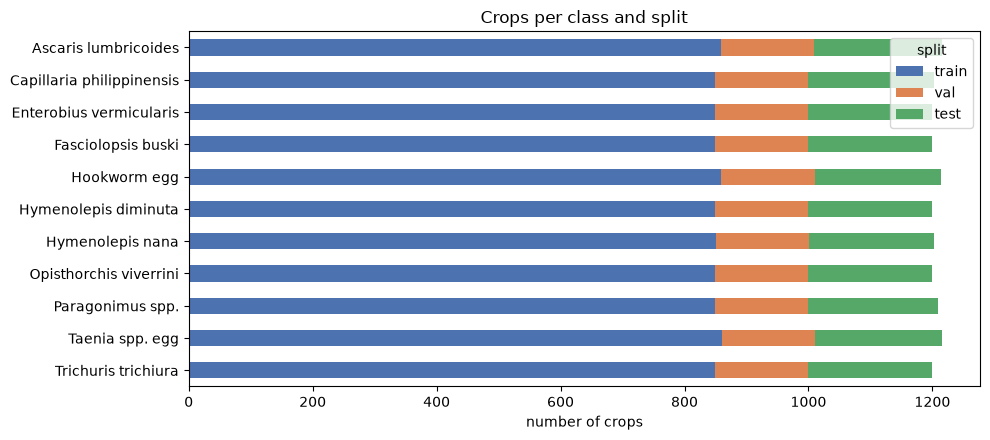

Training crops per class: min 850, max 860, ratio 1.012


In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
counts.drop(index="TOTAL").plot.barh(stacked=True, ax=ax, color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_xlabel("number of crops")
ax.set_ylabel("")
ax.invert_yaxis()
ax.set_title("Crops per class and split")
plt.tight_layout()
plt.savefig(PLOTS / "eda_class_distribution.png", dpi=120)
plt.show()
train_counts = counts.drop(index="TOTAL")["train"]
print(f"Training crops per class: min {train_counts.min()}, max {train_counts.max()}, "
      f"ratio {train_counts.max() / train_counts.min():.3f}")

**Interpretation.** The largest training class has only 1.2% more crops than the smallest (860 vs 850).
The dataset is **balanced**, so plain accuracy is meaningful and no class weights or resampling are needed.
Validation and test are balanced too, so macro and weighted averages will be almost identical.

### 7.2 Brightness (intensity) distribution

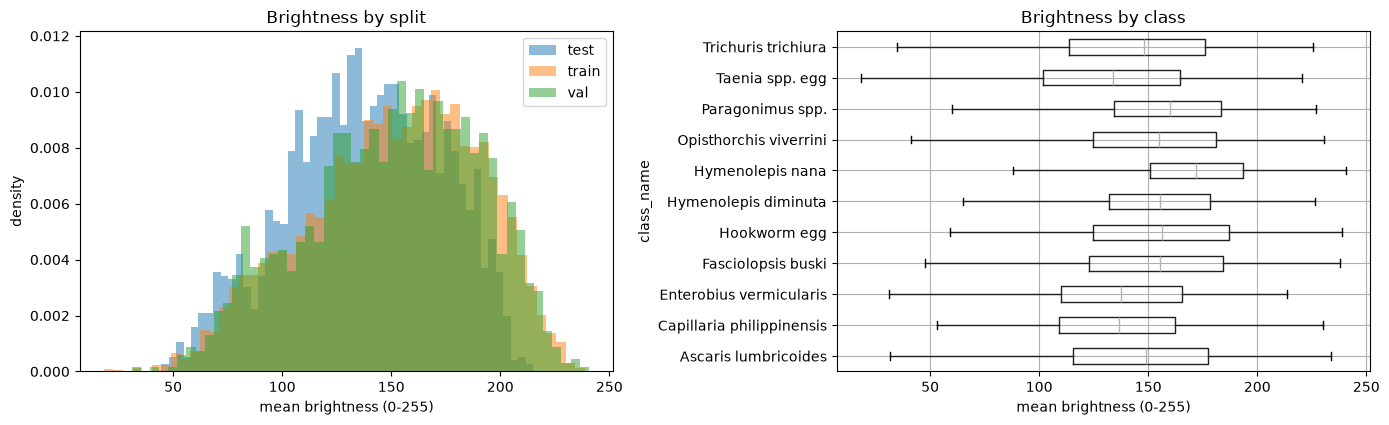

,brightness,contrast,sharpness
split,,,
test,138.2,29.1,1482.7
train,154.3,27.0,879.7
val,153.6,26.9,908.1


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for split, part in stats.groupby("split"):
    axes[0].hist(part["brightness"], bins=50, alpha=0.5, density=True, label=split)
axes[0].set_xlabel("mean brightness (0-255)")
axes[0].set_ylabel("density")
axes[0].legend()
axes[0].set_title("Brightness by split")
stats.boxplot(column="brightness", by="class_name", ax=axes[1], vert=False, showfliers=False)
axes[1].set_title("Brightness by class")
axes[1].set_xlabel("mean brightness (0-255)")
plt.suptitle("")
plt.tight_layout()
plt.savefig(PLOTS / "eda_brightness.png", dpi=120)
plt.show()
stats.groupby("split")[["brightness", "contrast", "sharpness"]].median().round(1)

### 7.3 Image dimensions and aspect ratio

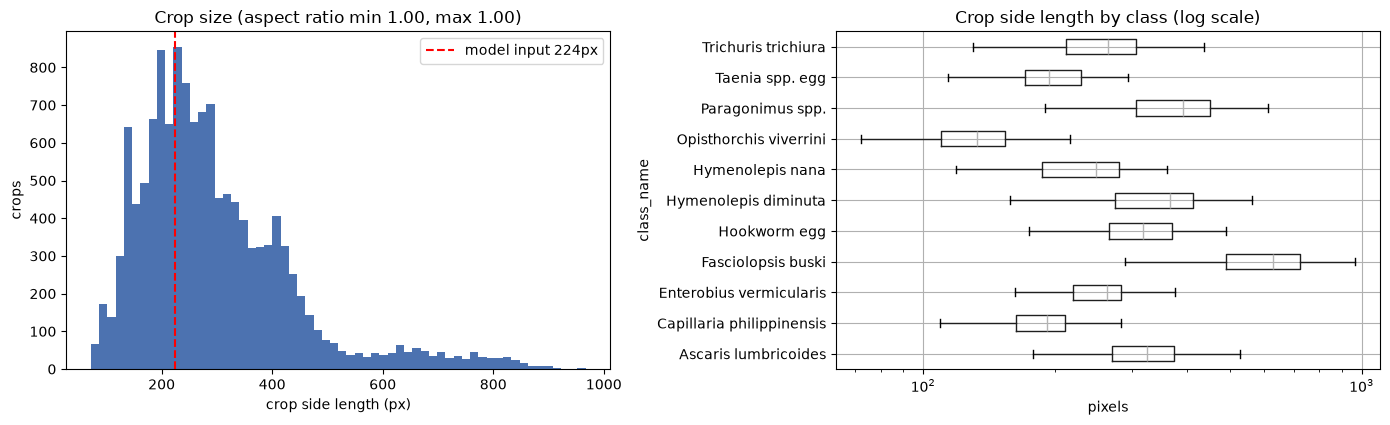

Crops smaller than 224px (will be upsampled): 34.2%


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(stats["width"], bins=60, color="#4C72B0")
axes[0].axvline(IMAGE_SIZE, color="red", linestyle="--", label=f"model input {IMAGE_SIZE}px")
axes[0].set_xlabel("crop side length (px)")
axes[0].set_ylabel("crops")
axes[0].legend()
axes[0].set_title(f"Crop size (aspect ratio min {stats.aspect_ratio.min():.2f}, max {stats.aspect_ratio.max():.2f})")
stats.boxplot(column="width", by="class_name", ax=axes[1], vert=False, showfliers=False)
axes[1].set_xscale("log")
axes[1].set_title("Crop side length by class (log scale)")
axes[1].set_xlabel("pixels")
plt.suptitle("")
plt.tight_layout()
plt.savefig(PLOTS / "eda_dimensions.png", dpi=120)
plt.show()
print(f"Crops smaller than {IMAGE_SIZE}px (will be upsampled): {(stats.width < IMAGE_SIZE).mean():.1%}")

### 7.4 Representative parasite images (random crops, 6 per class)

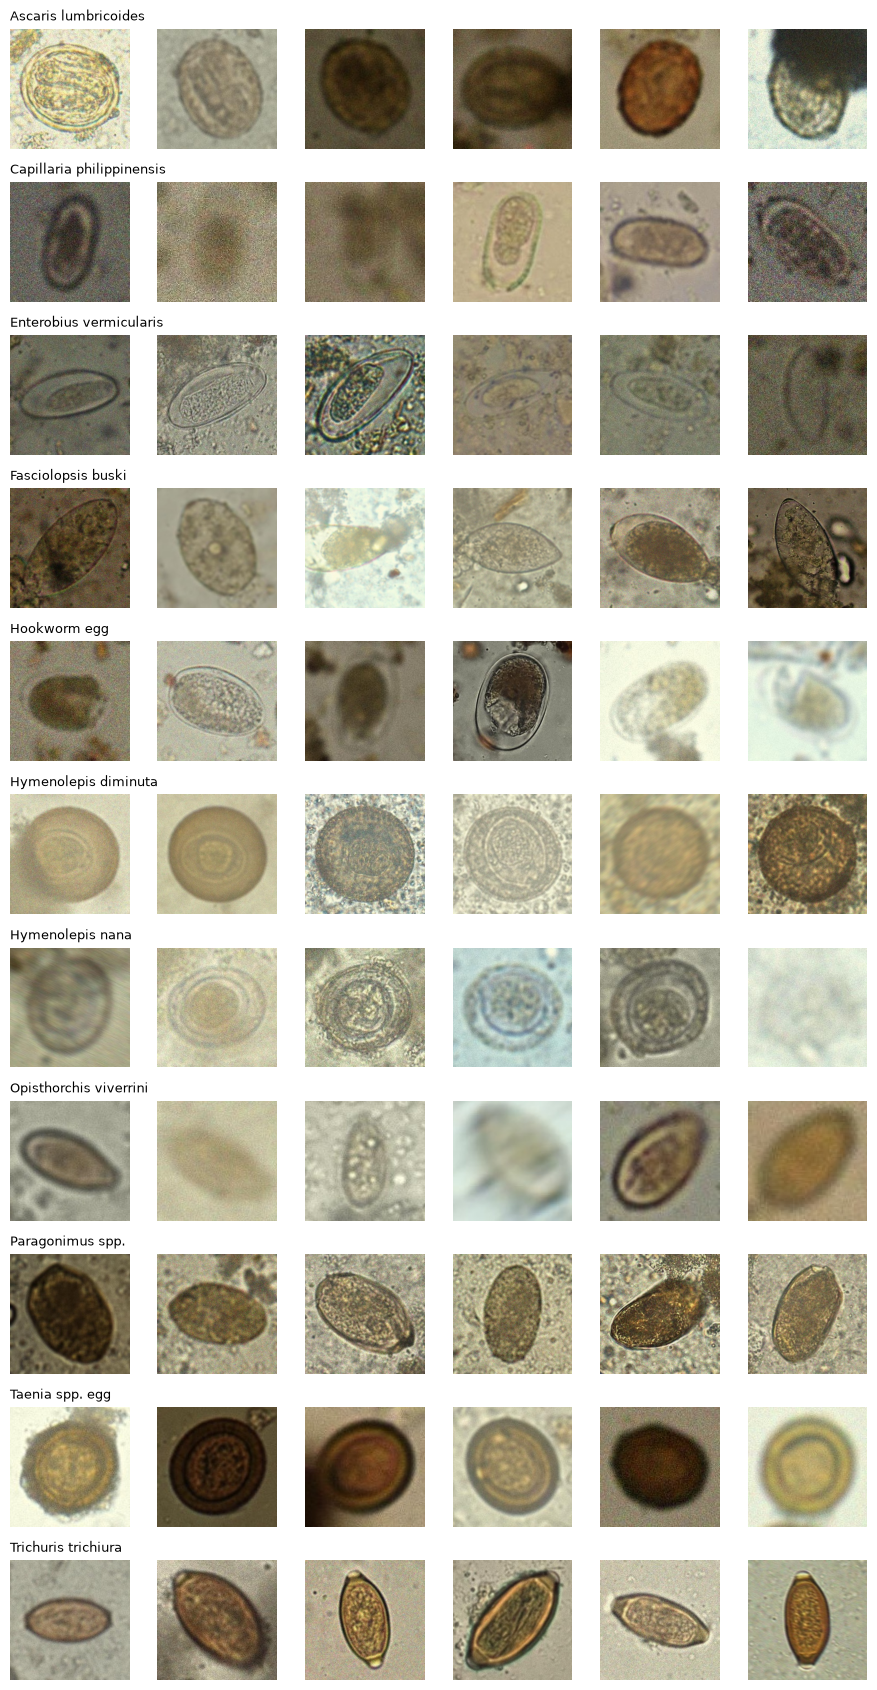

In [12]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(11, 6, figsize=(9, 17))
for class_id, name in enumerate(CLASS_NAMES):
    rows = manifest[(manifest.class_id == class_id) & (manifest.split == "train")]
    for col, path in enumerate(rng.choice(rows["crop_path"].values, 6, replace=False)):
        axes[class_id, col].imshow(Image.open(PROCESSED_DIR / path))
        axes[class_id, col].axis("off")
    axes[class_id, 0].set_title(name, fontsize=9, loc="left")
plt.tight_layout()
plt.savefig(PLOTS / "eda_examples.png", dpi=100)
plt.show()

## Section 8 — Interpretation of three image features

To judge whether a feature carries **class information**, we use *η² (eta squared)*: the share of the
feature's variance explained by the class. 0 means unrelated to class; 1 means fully determined by it.

In [13]:
def eta_squared(feature):
    group_mean = stats.groupby("class_name")[feature].transform("mean")
    return ((group_mean - stats[feature].mean()) ** 2).sum() / ((stats[feature] - stats[feature].mean()) ** 2).sum()


feature_table = pd.DataFrame({f: {"eta_squared": eta_squared(f), "median": stats[f].median(),
                                  "IQR": stats[f].quantile(0.75) - stats[f].quantile(0.25)}
                              for f in ["brightness", "contrast", "width", "sharpness", "saturation"]}).T.round(3)
feature_table

,eta_squared,median,IQR
brightness,0.076,151.177,56.838
contrast,0.278,27.409,13.982
width,0.755,265.000,163.000
sharpness,0.004,983.443,3677.743
saturation,0.144,53.134,32.930


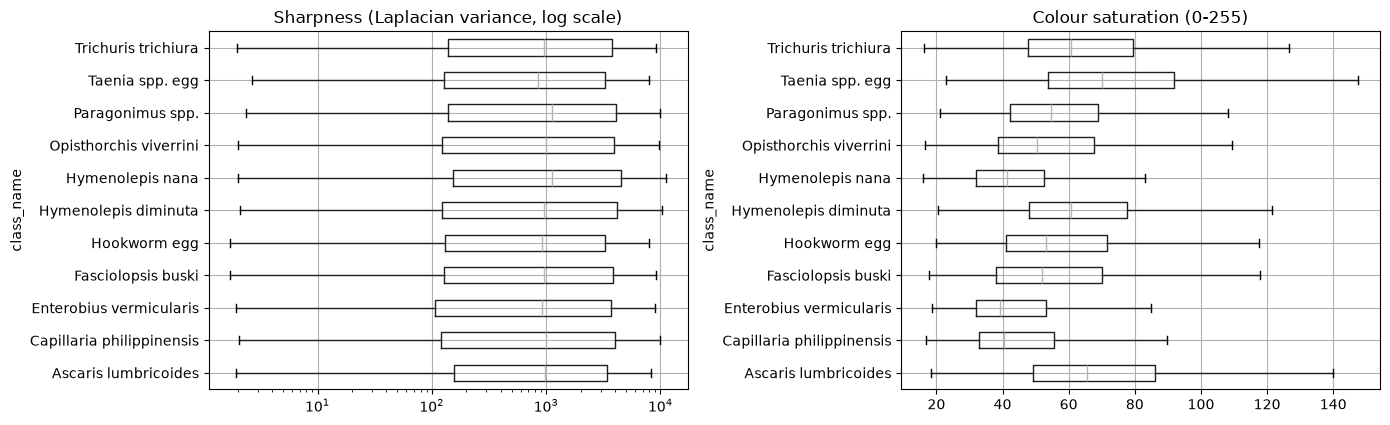

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
stats.boxplot(column="sharpness", by="class_name", ax=axes[0], vert=False, showfliers=False)
axes[0].set_xscale("log")
axes[0].set_title("Sharpness (Laplacian variance, log scale)")
stats.boxplot(column="saturation", by="class_name", ax=axes[1], vert=False, showfliers=False)
axes[1].set_title("Colour saturation (0-255)")
plt.suptitle("")
plt.tight_layout()
plt.savefig(PLOTS / "eda_texture_colour.png", dpi=120)
plt.show()

**Feature 1 — Brightness.** Mean brightness ranges from about 18 to 241 (median 151). The class explains only
**7.6%** of its variance: within every class there are dark and bright crops, so brightness reflects the
microscope, lamp and camera rather than the parasite. The held-out **test crops are darker** (median 138 vs
154 in train). *Implication:* a model relying on brightness would fail on other microscopes, and the test
set itself is shifted. We therefore use random brightness/contrast augmentation and expect some loss in
test performance.

**Feature 2 — Size and aspect ratio.** All crops are square by construction (aspect ratio exactly 1.0). Their
side length runs from 72 to 967 px, and 34% are smaller than the 224 px model input. Size is **strongly
class-dependent (η² = 0.755)**: *Fasciolopsis buski* crops have a median width of about 630 px, while
*Opisthorchis viverrini* is about 130 px. This matches real egg-size differences, but it also depends on
magnification. *Implication:* squaring before resizing protects egg shape. However, resizing everything to
224×224 removes absolute size, so the model must rely on shape and texture. Size-similar pairs such as the
two *Hymenolepis* species may therefore be harder to separate.

**Feature 3 — Texture/focus (Laplacian variance) and colour saturation.** Sharpness spans 1.7 to about
15,800 (log scale needed), and the class explains only **0.4%** of it. Focus quality depends on the
capture, not the species. Test crops are markedly **sharper** (median 1,483 vs 880). Saturation is
moderately class-related (**η² = 0.144**): some species' eggs are yellow-brown, others almost colourless.
*Limitation:* these are whole-crop averages. They mix egg and background debris, and a feature that differs
on average does not by itself let us classify single images. The overlapping boxes show none of them
separates the classes alone.

**Overall:** illumination and focus vary more *between capture setups* than *between classes*, and the
test set differs from the training set in both. This is a warning sign for generalisation that we check
again in Section 18.

## Section 9 — Image preprocessing

All of this lives in `src/preprocessing.py` and is shared with the API:

| Step | What | Why |
|---|---|---|
| Loading | decode JPEG/PNG to RGB (`tf.io.decode_image`, or Pillow in the API) | consistent 3-channel input, even for greyscale or transparent PNG uploads |
| Resizing | square crop → 224×224, bilinear with antialiasing (`resize_image`) | fixed input size for the CNN; crops are already square, so shapes are not distorted |
| Normalisation | **inside the model**: `Rescaling(1/255)` (baseline) or `Rescaling(1/127.5, -1)` (MobileNetV2) | normalisation happens exactly once and travels with the saved model |
| Label encoding | integer `class_id` 0–10 from the manifest (sparse labels) | stable mapping, independent of folder ordering |
| Augmentation | random flips, rotation, small shift/zoom, ±10% brightness and contrast — **training only** | eggs have no fixed orientation under the microscope, and brightness varies between microscopes (Section 8) |
| Batching | `tf.data`: parallel decode → batch 32 → prefetch | keeps the GPU busy without loading all images into memory |

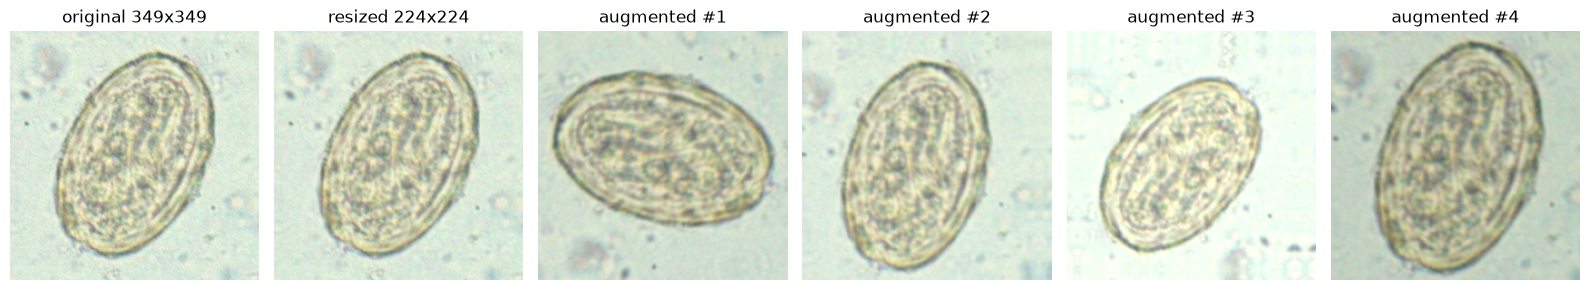

Model input: shape (1, 224, 224, 3) dtype float32 range (np.float32(97.35926), np.float32(252.63577))
Inside MobileNetV2 the Rescaling layer maps it to (np.float32(-0.23639798), np.float32(0.981457))


In [15]:
from src.preprocessing import build_augmentation, preprocess_pil_image

example_path = PROCESSED_DIR / manifest[manifest.split == "train"].iloc[0]["crop_path"]
original = Image.open(example_path).convert("RGB")
resized = preprocess_pil_image(original, IMAGE_SIZE)          # (1, 224, 224, 3) float32 in [0, 255]
augment = build_augmentation(SEED)
augmented = [augment(resized, training=True).numpy()[0] for _ in range(4)]

fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(original)
axes[0].set_title(f"original {original.width}x{original.height}")
axes[1].imshow(resized[0].astype("uint8"))
axes[1].set_title(f"resized {IMAGE_SIZE}x{IMAGE_SIZE}")
for i, image in enumerate(augmented):
    axes[i + 2].imshow(np.clip(image, 0, 255).astype("uint8"))
    axes[i + 2].set_title(f"augmented #{i + 1}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(PLOTS / "preprocessing_examples.png", dpi=110)
plt.show()
print("Model input: shape", resized.shape, "dtype", resized.dtype, "range", (resized.min(), resized.max()))
print("Inside MobileNetV2 the Rescaling layer maps it to", ((resized.min() / 127.5) - 1, (resized.max() / 127.5) - 1))

## Section 10 — Dataset preparation

Next we build the three `tf.data` pipelines and inspect one batch. **Leakage prevention:** we check that
no source photo contributes crops to more than one split, and the audit (`reports/dataset_audit.md`) found
0 exact and 0 near-duplicate photos across splits.

In [16]:
from src.preprocessing import list_split, make_dataset

train_files, train_labels = list_split(PROCESSED_DIR, "train")
val_files, val_labels = list_split(PROCESSED_DIR, "val")
test_files, test_labels = list_split(PROCESSED_DIR, "test")
train_ds = make_dataset(train_files, train_labels, IMAGE_SIZE, BATCH_SIZE, training=True, seed=SEED)
val_ds = make_dataset(val_files, val_labels, IMAGE_SIZE, BATCH_SIZE, training=False)

images, labels = next(iter(train_ds))
print("train / val / test images:", len(train_files), len(val_files), len(test_files))
print("batch images:", images.shape, images.dtype, "| batch labels:", labels.shape, labels.dtype,
      "| label range:", int(tf.reduce_min(labels)), "-", int(tf.reduce_max(labels)))

overlap = manifest[manifest.split != "test"].groupby("source_image")["split"].nunique()
print("Source photos appearing in both train and val:", int((overlap > 1).sum()))
print("Test crops come from the official test photos (separate files and naming scheme).")

train / val / test images: 9379 1652 2228
batch images: (32, 224, 224, 3) <dtype: 'float32'> | batch labels: (32,) <dtype: 'int32'> | label range: 0 - 10
Source photos appearing in both train and val: 0
Test crops come from the official test photos (separate files and naming scheme).


## Section 11 — Baseline CNN

A deliberately small custom network (`src/model.py::build_baseline_cnn`):

* **Rescaling** — pixels to [0, 1].
* **4 convolution blocks** (32 → 64 → 128 → 256 filters). Each block is Conv 3×3 → BatchNorm → ReLU → MaxPool.
  Early blocks learn edges and colours; later blocks learn shell outlines and internal texture.
  Each max-pool halves the resolution.
* **Global average pooling** — one number per filter. It has far fewer parameters than `Flatten`, which limits overfitting.
* **Dropout 0.3** — randomly drops features during training (regularisation).
* **Dense softmax (11)** — one probability per class.

In [17]:
from src.model import build_baseline_cnn, count_parameters

baseline_preview = build_baseline_cnn(IMAGE_SIZE, len(CLASS_NAMES))
baseline_preview.summary()
print(count_parameters(baseline_preview))

Model: "ovascope_baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_0_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 11)             │         2,827 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 392,683 (1.50 MB)

 Trainable params: 391,723 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

{'total': 392683, 'trainable': 391723, 'non_trainable': 960}


## Section 12 — Baseline training

* **Optimiser:** Adam, learning rate 1e-3. It adapts per-parameter step sizes and is a robust default.
* **Loss:** sparse categorical cross-entropy (integer labels, softmax outputs).
* **Epochs:** up to 30, with these callbacks:
  * **EarlyStopping** (patience 5, on validation loss), which **restores the best weights**
  * **ReduceLROnPlateau**, which halves the learning rate after 2 stagnant epochs
  * **ModelCheckpoint**, which keeps the best epoch
  * **BackupAndRestore**, which lets an interrupted run resume
* **No class weights:** Section 7 shows the classes are balanced.

`src.train.train_baseline` runs this and saves the result as a new model version. The log below is the
actual training output.

In [18]:
from src.train import train_baseline

baseline_version = train_baseline(cfg)
baseline_version

Epoch 1/30


/home/maurice/anaconda3/envs/ovascope/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


E0000 00:00:1795432560.607742   76722 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1795432601.393472   76720 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


294/294 - 58s - 196ms/step - accuracy: 0.2216 - loss: 2.2035 - val_accuracy: 0.0908 - val_loss: 3.1897 - learning_rate: 0.0010


Epoch 2/30


... (55 outputs left out)

Epoch 30/30


294/294 - 38s - 130ms/step - accuracy: 0.8224 - loss: 0.5265 - val_accuracy: 0.8608 - val_loss: 0.4305 - learning_rate: 3.1250e-05


Baseline CNN validation: accuracy=0.8608 macro_f1=0.8601


'v001_baseline_cnn'

## Section 13 — Baseline evaluation (validation set)

At least four metrics are required. We report **accuracy, loss, macro precision, macro recall, macro F1**,
balanced accuracy and per-class scores. *Macro* averages give every parasite class equal weight. They are
computed on the **validation** set; the test set is still untouched.

{
 "accuracy": 0.8608,
 "loss": 0.4305,
 "macro_precision": 0.8616,
 "macro_recall": 0.8607,
 "macro_f1": 0.8601,
 "balanced_accuracy": 0.8607
}


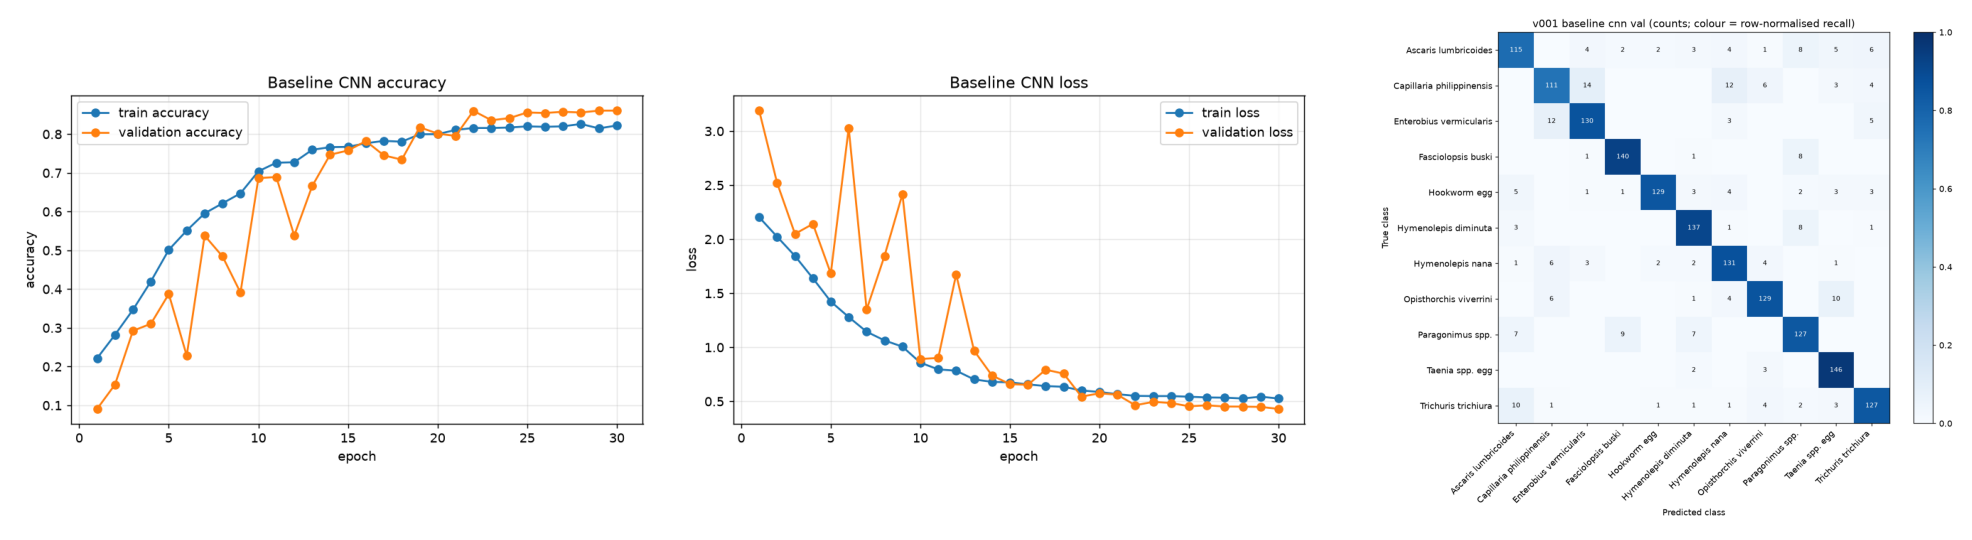

,precision,recall,f1-score,support
Ascaris lumbricoides,0.816,0.767,0.790,150.000
Capillaria philippinensis,0.816,0.740,0.776,150.000
Enterobius vermicularis,0.850,0.867,0.858,150.000
Fasciolopsis buski,0.921,0.933,0.927,150.000
Hookworm egg,0.963,0.854,0.905,151.000
Hymenolepis diminuta,0.873,0.913,0.893,150.000
Hymenolepis nana,0.819,0.873,0.845,150.000
Opisthorchis viverrini,0.878,0.860,0.869,150.000
Paragonimus spp.,0.819,0.847,0.833,150.000
Taenia spp. egg,0.854,0.967,0.907,151.000


In [19]:
import json

from src import registry
from src.evaluation import evaluate_model, measure_inference_time, plot_history


def load_version(version):
    folder = registry.version_path(cfg["paths"]["models_dir"], version)
    return tf.keras.models.load_model(folder / "model.keras", compile=False), folder


def summary_row(metrics):
    return {k: round(metrics[k], 4) for k in ("accuracy", "loss", "macro_precision", "macro_recall", "macro_f1",
                                              "balanced_accuracy")}


baseline_model, baseline_folder = load_version(baseline_version)
baseline_history = pd.read_csv(baseline_folder / "training_history.csv")
plot_history(baseline_history, PLOTS / f"{baseline_version}_accuracy_curve.png",
             PLOTS / f"{baseline_version}_loss_curve.png", title="Baseline CNN")
baseline_val = evaluate_model(baseline_model, val_files, val_labels, CLASS_NAMES, IMAGE_SIZE, BATCH_SIZE,
                              METRICS, f"{baseline_version}_val", plot_examples=False)
print(json.dumps(summary_row(baseline_val), indent=1))
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, name in zip(axes, [f"{baseline_version}_accuracy_curve.png", f"{baseline_version}_loss_curve.png",
                           f"{baseline_version}_val_confusion_matrix.png"]):
    ax.imshow(Image.open((PLOTS if "curve" in name else METRICS) / name))
    ax.axis("off")
plt.tight_layout()
plt.show()
pd.read_csv(METRICS / f"{baseline_version}_val_classification_report.csv", index_col=0).round(3)

**Interpretation.** The baseline CNN reaches **0.861 validation accuracy and 0.860 macro-F1** after 30 epochs.
* **Learning dynamics:** validation loss started high (3.19 after epoch 1) and was unstable for the first
  epochs while BatchNorm statistics settled at learning rate 1e-3. ReduceLROnPlateau lowered the rate
  step by step, and validation loss then fell steadily to 0.431.
* **Not overfitting:** final training accuracy (0.822, measured *with* augmentation and dropout) is
  *below* validation accuracy (0.861), so the network is not memorising the training set.
* **Possibly under-trained:** the best epoch was the last one (30) and early stopping never triggered.
  The baseline was still improving when the 30-epoch budget ran out.
* **Run-to-run variation:** three complete runs of this notebook gave baseline validation macro-F1 of
  0.843, 0.890 and 0.860. Seeds are fixed, but GPU kernels are not fully deterministic, and a small CNN
  trained from scratch is sensitive to that. Differences of a few points between baseline runs are noise.
* **Per class:** F1 is lowest for *Capillaria* (0.78), *Ascaris* (0.79) and *Paragonimus* (0.83), and
  highest for *Fasciolopsis* (0.93), *Taenia* (0.91) and *Hookworm* (0.91).

## Section 14 — Improved model: MobileNetV2 transfer learning

**Why MobileNetV2?** It has about 3.5 M parameters (around 14 MB), is fast on a CPU (so cheap to deploy), and its
ImageNet features (edges, textures, shapes) transfer well to microscopy. EfficientNetB0 is a little more
accurate on ImageNet, but slower on CPU, and Keras's version hides its own input rescaling inside the
model, which makes double normalisation an easy mistake. We train only this one backbone rather than
trying several large ones.

* **Pretrained weights:** ImageNet (downloaded once by Keras and cached). If a platform has no internet,
  `build_transfer_model(weights=<local .h5 path>)` uses a local copy. The cell fails loudly rather than
  silently using random weights.
* **Custom head:** global average pooling → dropout 0.3 → dense softmax (11).
* **Stage 1 (head):** backbone **frozen**, so only the head learns (lr 1e-3).
* **Stage 2 (fine-tuning):** layers ≥ 100 of 154 unfrozen, lr **1e-5**. The upper layers hold
  ImageNet-specific shapes worth adapting; the lower layers hold generic edges, so they stay frozen.
  **BatchNorm layers stay frozen** and the backbone runs in inference mode. Updating BN statistics
  with small batches would erase the pretrained features.

In [20]:
from src.model import build_transfer_model, get_backbone

transfer_preview = build_transfer_model(IMAGE_SIZE, len(CLASS_NAMES))
transfer_preview.summary()
backbone = get_backbone(transfer_preview)
print("Backbone layers:", len(backbone.layers), "| trainable now:", sum(l.trainable for l in backbone.layers))
print(count_parameters(transfer_preview))

Model: "ovascope_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_minus1_1 (Rescaling)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_pool                       │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 11)             │        14,091 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,272,075 (8.67 MB)

 Trainable params: 14,091 (55.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Backbone layers: 154 | trainable now: 0
{'total': 2272075, 'trainable': 14091, 'non_trainable': 2257984}


## Section 15 — Improved model training  &  Section 16 — Fine-tuning

`src.train.train_transfer` trains the head and saves the best head checkpoint. It then fine-tunes and
evaluates **both** stages on validation data, and keeps whichever has the higher validation macro-F1.
The log below is the actual training output of both stages.

In [21]:
from src.train import train_transfer

transfer_version = train_transfer(cfg)
transfer_model, transfer_folder = load_version(transfer_version)
transfer_meta = json.loads((transfer_folder / "model_metadata.json").read_text())
pd.Series(transfer_meta["fine_tuning"]).to_frame("value")

Epoch 1/15


/home/maurice/anaconda3/envs/ovascope/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


294/294 - 53s - 181ms/step - accuracy: 0.6600 - loss: 1.0080 - val_accuracy: 0.8099 - val_loss: 0.6077 - learning_rate: 0.0010


Epoch 2/15


294/294 - 28s - 94ms/step - accuracy: 0.8055 - loss: 0.5528 - val_accuracy: 0.8305 - val_loss: 0.5204 - learning_rate: 0.0010


Epoch 3/15


... (55 outputs left out)

Epoch 15/15


294/294 - 30s - 103ms/step - accuracy: 0.9529 - loss: 0.1363 - val_accuracy: 0.9207 - val_loss: 0.2523 - learning_rate: 5.0000e-06


Fine-tuned validation: accuracy=0.9195 macro_f1=0.9200


,value
performed,True
unfrozen_from_layer,100
trainable_backbone_layers,36
head_val_macro_f1,0.862889
fine_tuned_val_macro_f1,0.920035
head_val_accuracy,0.862591
fine_tuned_val_accuracy,0.919492
kept,fine_tune


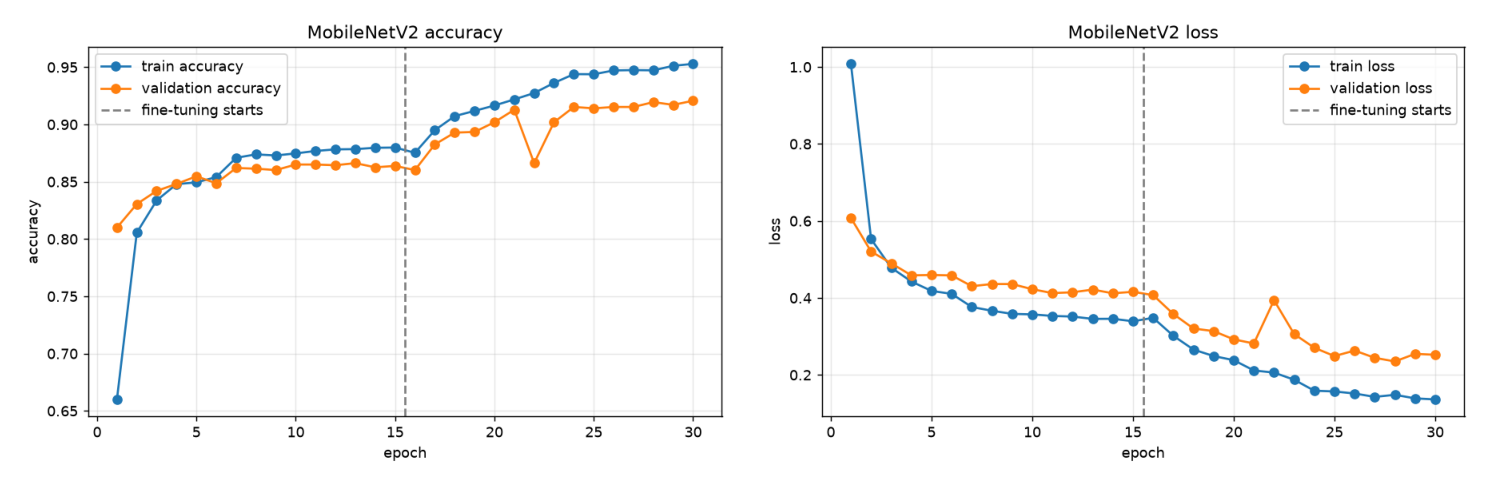

,epoch,phase,loss,accuracy,val_loss,val_accuracy,learning_rate
0,1,head,1.0080,0.6600,0.6077,0.8099,0.0010
1,2,head,0.5528,0.8055,0.5204,0.8305,0.0010
2,3,head,0.4785,0.8337,0.4900,0.8420,0.0010
3,4,head,0.4426,0.8479,0.4586,0.8481,0.0010
4,5,head,0.4182,0.8495,0.4595,0.8547,0.0010
5,6,head,0.4105,0.8540,0.4585,0.8487,0.0010
6,7,head,0.3764,0.8709,0.4304,0.8620,0.0005
7,8,head,0.3667,0.8739,0.4362,0.8614,0.0005
8,9,head,0.3586,0.8729,0.4360,0.8602,0.0005
9,10,head,0.3572,0.8747,0.4226,0.8650,0.0003


In [22]:
transfer_history = pd.read_csv(transfer_folder / "training_history.csv")
plot_history(transfer_history, PLOTS / f"{transfer_version}_accuracy_curve.png",
             PLOTS / f"{transfer_version}_loss_curve.png", title="MobileNetV2")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, name in zip(axes, ["accuracy", "loss"]):
    ax.imshow(Image.open(PLOTS / f"{transfer_version}_{name}_curve.png"))
    ax.axis("off")
plt.tight_layout()
plt.show()
transfer_history[["epoch", "phase", "loss", "accuracy", "val_loss", "val_accuracy", "learning_rate"]].round(4)

**Interpretation.**
* **Head only (frozen backbone):** validation accuracy reached 0.81 after a *single* epoch, which shows how
  useful the ImageNet features are. It plateaued at **macro-F1 0.863**, about the same as the baseline.
* **Fine-tuning** (layers ≥ 100 unfrozen, lr 1e-5) raised validation macro-F1 to **0.920**, a gain of 5.7
  points. The fine-tuned model was therefore kept.
* **Restored weights:** the lowest validation loss (0.235) came at epoch 28 (fine-tuning epoch 13).
  EarlyStopping restored those weights at the end of training.
* **Curves:** validation loss tracks training loss closely during the head stage. During fine-tuning,
  training loss keeps falling (0.14 at the end) while validation loss flattens around 0.24–0.25, apart from
  one spike at epoch 22. This is the start of **mild overfitting**, so more epochs at this learning rate
  would bring little.

## Section 17 — Model comparison and selection (validation data only)

Both candidates are compared on the **validation** set together with model size and single-image latency.
The final model is chosen by **validation macro-F1**, with deployment cost as a tie-breaker. The test set
plays no role in this choice.

In [23]:
from src.train import select_best

transfer_val = evaluate_model(transfer_model, val_files, val_labels, CLASS_NAMES, IMAGE_SIZE, BATCH_SIZE,
                              METRICS, f"{transfer_version}_val", plot_examples=False)
rows = []
for version, model, metrics in [(baseline_version, baseline_model, baseline_val),
                                (transfer_version, transfer_model, transfer_val)]:
    meta = json.loads((registry.version_path(cfg["paths"]["models_dir"], version) / "model_metadata.json").read_text())
    with tf.device("/CPU:0"):
        cpu_latency = measure_inference_time(model, IMAGE_SIZE)["median_ms"]
    rows.append({"model": meta["architecture"], "version": version, **summary_row(metrics),
                 "parameters": meta["parameters"]["total"], "size_MB": meta["model_size_mb"],
                 "CPU_latency_ms": round(cpu_latency, 1),
                 "accel_latency_ms": round(measure_inference_time(model, IMAGE_SIZE)["median_ms"], 1),
                 "epochs": meta["epochs_completed"], "train_minutes": round(meta["training_seconds"] / 60, 1)})
comparison = pd.DataFrame(rows)
comparison.to_csv(METRICS / "model_comparison.csv", index=False)

final_version = select_best(cfg, [baseline_version, transfer_version])
registry.activate_version(cfg["paths"]["models_dir"], final_version)
comparison

Validation macro-F1: {'v001_baseline_cnn': 0.8601078782977818, 'v002_mobilenetv2': 0.9200345936748903} -> selected v002_mobilenetv2


,model,version,accuracy,loss,macro_precision,macro_recall,macro_f1,balanced_accuracy,parameters,size_MB,CPU_latency_ms,accel_latency_ms,epochs,train_minutes
0,ovascope_baseline_cnn,v001_baseline_cnn,0.8608,0.4305,0.8616,0.8607,0.8601,0.8607,392683,4.79,7.0,1.4,30,19.1
1,ovascope_mobilenetv2,v002_mobilenetv2,0.9195,0.2350,0.9227,0.9195,0.9200,0.9195,2272075,24.53,11.8,3.7,30,13.8


**Interpretation and decision.** MobileNetV2 has the higher validation macro-F1 (**0.920 vs 0.860**) and
higher accuracy, precision and recall, a margin larger than the run-to-run variation seen for the
baseline. It is 5× larger on disk (24.5 MB vs 4.8 MB). Its compiled single-image latency is still small:
**11.8 ms on CPU** vs 7.0 ms for the baseline, and 3.7 vs 1.4 ms on GPU. That is negligible next to network and
image-decoding time in the API. We therefore select **`v002_mobilenetv2`** and activate it. The decision
uses validation data only.

## Section 18 — Final held-out test evaluation

The selected model is evaluated **once** on the protected test set: 2,228 crops from the official test
photos, which were never used for training, early stopping or model selection.

In [24]:
import shutil

final_model, final_folder = load_version(final_version)
test_metrics = evaluate_model(final_model, test_files, test_labels, CLASS_NAMES, IMAGE_SIZE, BATCH_SIZE,
                              METRICS, "final_test")
for name in ("final_test_confusion_matrix.png", "final_test_predictions.png"):
    shutil.move(METRICS / name, PLOTS / name)
test_metrics["model_version"] = final_version
(METRICS / "final_test_metrics.json").write_text(json.dumps(test_metrics, indent=2))

from src.train import update_metadata
update_metadata(cfg, final_version, test_metrics={k: v for k, v in test_metrics.items()
                                                  if k not in ("per_class", "confusion_matrix", "top_confusions")})
registry.activate_version(cfg["paths"]["models_dir"], final_version)   # refresh stable-name copies
shutil.copy(final_folder / "model_metadata.json", cfg["paths"]["models_dir"] / "model_metadata.json")
shutil.copy(final_folder / "training_config.json", cfg["paths"]["models_dir"] / "training_config.json")

print(json.dumps(summary_row(test_metrics), indent=1))
pd.DataFrame(test_metrics["per_class"]).T.round(3)

{
 "accuracy": 0.8371,
 "loss": 0.5154,
 "macro_precision": 0.8479,
 "macro_recall": 0.838,
 "macro_f1": 0.837,
 "balanced_accuracy": 0.838
}


,precision,recall,f1,support
Ascaris lumbricoides,0.731,0.749,0.740,207.0
Capillaria philippinensis,0.760,0.685,0.720,203.0
Enterobius vermicularis,0.780,0.940,0.853,200.0
Fasciolopsis buski,0.830,0.955,0.888,199.0
Hookworm egg,0.957,0.873,0.913,204.0
Hymenolepis diminuta,0.701,0.975,0.816,200.0
Hymenolepis nana,0.849,0.723,0.781,202.0
Opisthorchis viverrini,0.857,0.870,0.864,200.0
Paragonimus spp.,0.892,0.713,0.793,209.0
Taenia spp. egg,0.970,0.946,0.958,204.0


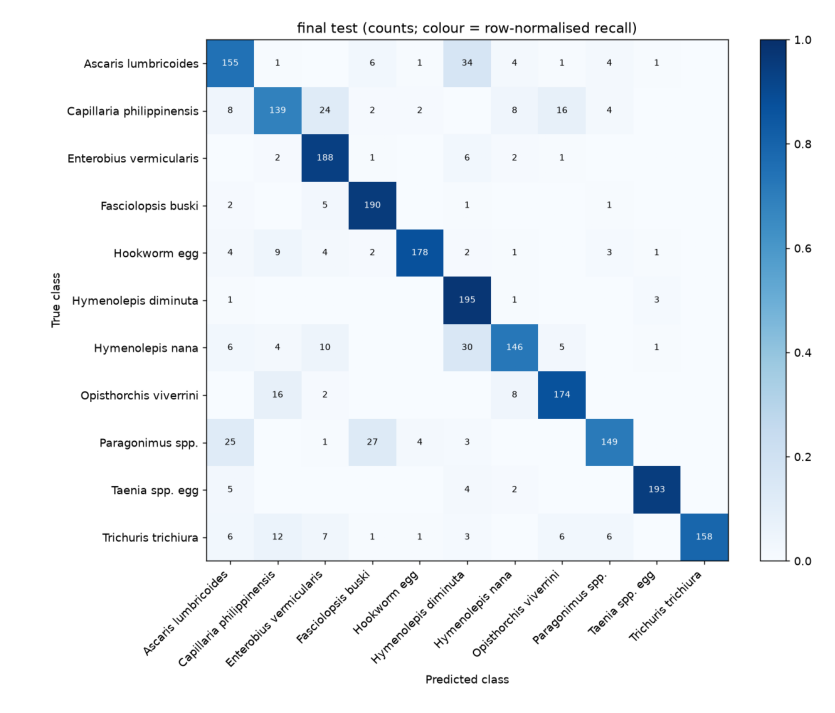

,true,predicted,count
0,Ascaris lumbricoides,Hymenolepis diminuta,34
1,Hymenolepis nana,Hymenolepis diminuta,30
2,Paragonimus spp.,Fasciolopsis buski,27
3,Paragonimus spp.,Ascaris lumbricoides,25
4,Capillaria philippinensis,Enterobius vermicularis,24


In [25]:
plt.figure(figsize=(11, 9))
plt.imshow(Image.open(PLOTS / "final_test_confusion_matrix.png"))
plt.axis("off")
plt.show()
pd.DataFrame(test_metrics["top_confusions"])

In [26]:
val_vs_test = pd.DataFrame({"validation": summary_row(transfer_val if final_version == transfer_version else baseline_val),
                            "test": summary_row(test_metrics)})
val_vs_test["difference"] = val_vs_test["test"] - val_vs_test["validation"]
val_vs_test

,validation,test,difference
accuracy,0.9195,0.8371,-0.0824
loss,0.2350,0.5154,0.2804
macro_precision,0.9227,0.8479,-0.0748
macro_recall,0.9195,0.8380,-0.0815
macro_f1,0.9200,0.8370,-0.0830
balanced_accuracy,0.9195,0.8380,-0.0815


**Interpretation — generalisation.** On the 2,228 protected test crops the selected model reaches
**accuracy 0.837, macro precision 0.848, macro recall 0.838, macro-F1 0.837 and loss 0.515**. That is about
**8 points below validation** (0.920). This gap is the most important finding of the evaluation.

* **Systematic confusions:**
  - *Ascaris* → *Hymenolepis diminuta* (34) and *H. nana* → *H. diminuta* (30). *H. diminuta* has recall
    0.98 but precision 0.70, so the model over-uses it for roundish eggs.
  - *Paragonimus* → *Fasciolopsis* (27) and → *Ascaris* (25). *Paragonimus* recall is 0.71.
  - *Capillaria* → *Enterobius* (24). *Capillaria* is the weakest class (recall 0.69, F1 0.72).
  - *Trichuris* is never wrongly predicted (precision 1.00), but 21% of *Trichuris* eggs are missed.
* **Why lower than validation?** Validation photos come from the *same* official training collection as
  the training photos. Test photos are a separately released set that differs measurably:
  - It is darker and sharper on average (Section 8).
  - It has a different camera mix: 50% of test crops come from three high-resolution phone formats
    (vs 30% of training crops), and three formats seen in training are absent.
  - `scripts/analyze_test_errors.py` shows accuracy on those phone formats dropping from 0.92–0.95
    (validation) to 0.79–0.82 (test). The other formats stay at 0.83–0.90 on test.

  The gap is therefore mainly a **distribution shift between acquisition sets**. Leakage is ruled out by
  the audit, and it is not overfitting to the training images.
* **What it means:** validation accuracy overstates performance on new capture conditions. The test
  figure, **≈0.84**, is the honest estimate for this model. Over three complete runs the test macro-F1 was
  0.811, 0.821 and 0.837. Training on more diverse capture conditions would likely matter more than a
  larger network.

## Section 19 — Prediction demonstration

The **saved** model is reloaded through `src.prediction.Predictor`, the same class the API uses. It then
classifies randomly drawn, genuinely labelled test crops. The examples are random, not hand-picked, so
errors are shown if they occur. The second figure (made during evaluation) shows correct,
incorrect and lowest-confidence test predictions.

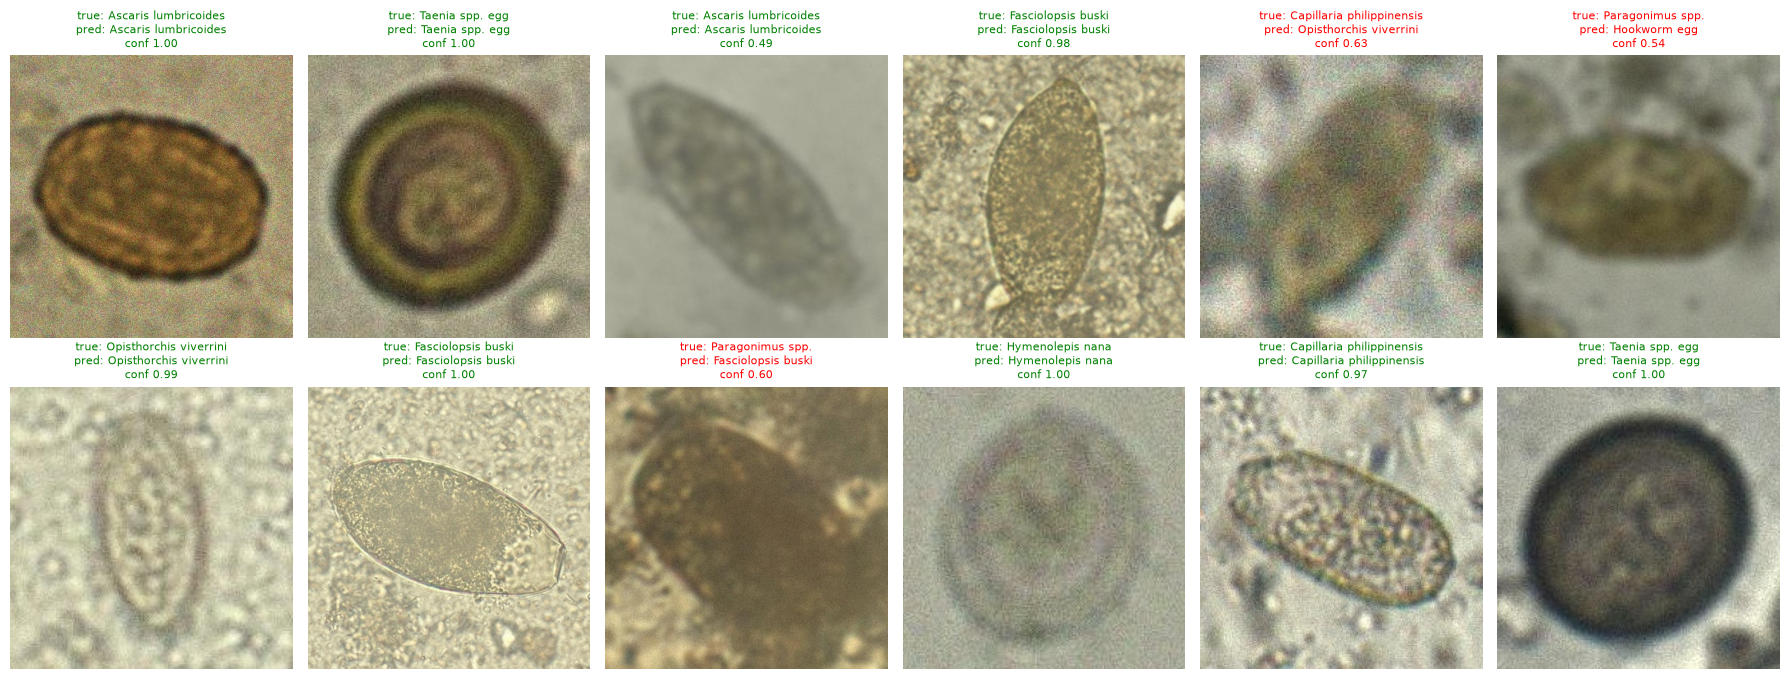

Model version used: v002_mobilenetv2


,crop,true,predicted,confidence,correct
0,1054_ann102,Ascaris lumbricoides,Ascaris lumbricoides,1.000,True
1,1670_ann1002,Taenia spp. egg,Taenia spp. egg,1.000,True
2,0521_ann25,Ascaris lumbricoides,Ascaris lumbricoides,0.493,True
3,1140_ann1779,Fasciolopsis buski,Fasciolopsis buski,0.978,True
4,0745_ann1213,Capillaria philippinensis,Opisthorchis viverrini,0.628,False
5,1217_ann837,Paragonimus spp.,Hookworm egg,0.543,False
6,0526_ann1906,Opisthorchis viverrini,Opisthorchis viverrini,0.988,True
7,1655_ann1789,Fasciolopsis buski,Fasciolopsis buski,1.000,True
8,0004_ann2014,Paragonimus spp.,Fasciolopsis buski,0.604,False
9,0348_ann478,Hymenolepis nana,Hymenolepis nana,0.998,True


In [27]:
from src.prediction import Predictor

predictor = Predictor.from_active(cfg)
demo_rows = manifest[manifest.split == "test"].sample(12, random_state=7)
fig, axes = plt.subplots(2, 6, figsize=(18, 7))
results = []
for ax, (_, row) in zip(axes.flat, demo_rows.iterrows()):
    result = predictor.predict_file(PROCESSED_DIR / row["crop_path"])
    correct = result["predicted_class_id"] == row["class_id"]
    results.append({"crop": row["crop_id"], "true": row["class_name"], "predicted": result["predicted_class"],
                    "confidence": round(result["confidence"], 3), "correct": correct})
    ax.imshow(Image.open(PROCESSED_DIR / row["crop_path"]))
    ax.set_title(f"true: {row['class_name']}\npred: {result['predicted_class']}\nconf {result['confidence']:.2f}",
                 fontsize=8, color="green" if correct else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Model version used:", predictor.version)
pd.DataFrame(results)

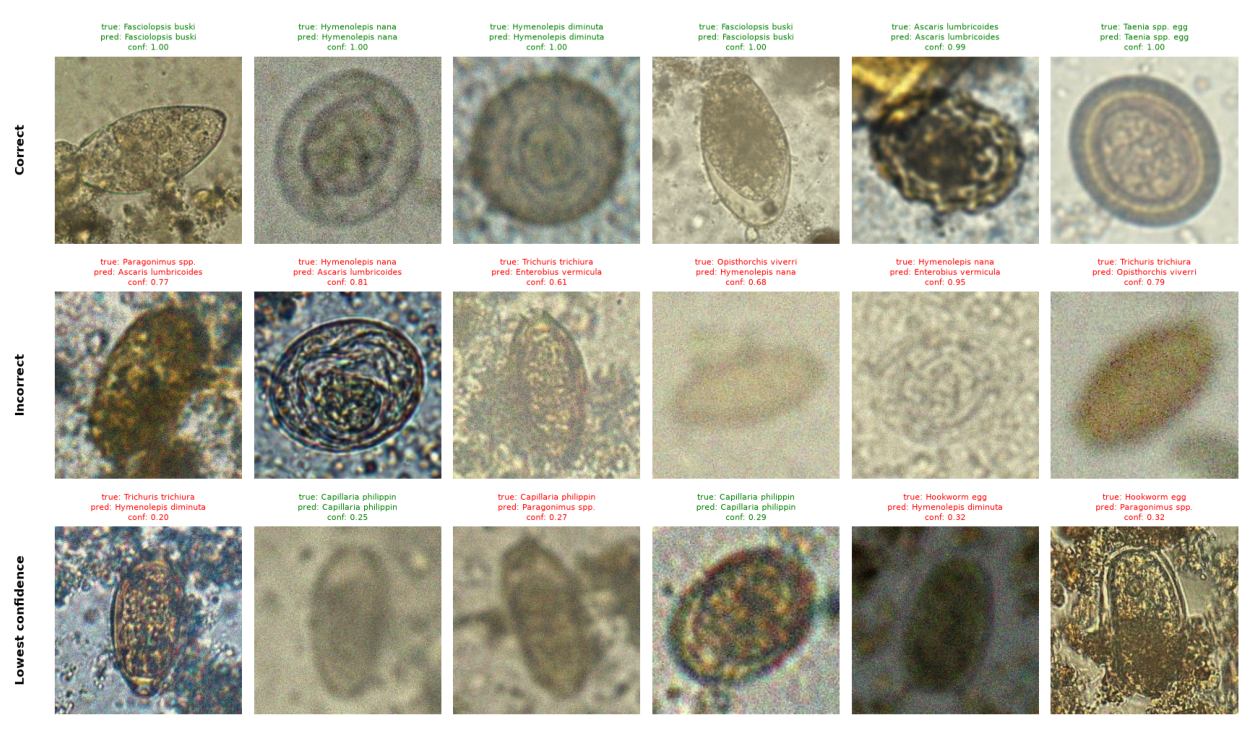

In [28]:
plt.figure(figsize=(16, 9.5))
plt.imshow(Image.open(PLOTS / "final_test_predictions.png"))
plt.axis("off")
plt.show()

**Interpretation.** The reloaded model correctly classified **9 of the 12 randomly drawn test crops**. The 3
errors are *Capillaria* → *Opisthorchis* (confidence 0.63), *Paragonimus* → *Hookworm* (0.54) and
*Paragonimus* → *Fasciolopsis* (0.60). All three had confidence ≤ 0.63, while 8 of the 9 correct predictions
scored above 0.95. In this sample a low score is a useful warning, but it is **not a guarantee**: one
correct prediction scored only 0.49, and the larger evaluation also contains confident errors (e.g.
*H. nana* → *Enterobius* at 0.95 in the second figure).

In the second figure, most incorrect and lowest-confidence examples are blurred, faint or dark eggs.
Two of the lowest-confidence ones, however, are sharp eggs (a *Trichuris* and a hookworm egg) on busy,
debris-filled backgrounds. Poor focus is one cause of uncertainty, but not the only one.

## Section 20 — Saving the model

Every version folder contains the native **`.keras`** model (the primary format) and an **`.h5`** export.
The `.h5` file was written with `model.save("model.h5")`, not renamed. Both files are reloaded below
and must give the same predictions. The folder also holds the class mapping, configuration, training
history, metadata (with SHA-256 checksums) and the model summary.

In [29]:
for path in sorted(final_folder.iterdir()):
    print(f"{path.name:28s} {path.stat().st_size / 1e6:8.2f} MB")
sample = next(iter(make_dataset(test_files[:8], test_labels[:8], IMAGE_SIZE, 8, training=False)))[0]
reloaded_keras = tf.keras.models.load_model(final_folder / "model.keras", compile=False)
reloaded_h5 = tf.keras.models.load_model(final_folder / "model.h5", compile=False)
difference = np.abs(reloaded_keras.predict(sample, verbose=0) - reloaded_h5.predict(sample, verbose=0)).max()
print("Max difference between .keras and .h5 predictions:", difference)
print("Active model pointer:", json.loads((cfg["paths"]["models_dir"] / "active_model.json").read_text()))

class_mapping.json               0.00 MB
model.h5                        24.31 MB
model.keras                     24.53 MB
model_metadata.json              0.00 MB
model_summary.txt                0.00 MB
training_config.json             0.00 MB
training_history.csv             0.00 MB


Max difference between .keras and .h5 predictions: 0.0
Active model pointer: {'version': 'v002_mobilenetv2', 'previous': None, 'activated_at': '2026-11-23T11:49:48+00:00'}


## Section 21 — Retraining readiness

The application retrains by **loading the saved OvaScope model** and continuing training. It never
starts from a randomly initialised network. The full process lives in `src/retrain.py`:

1. Labelled images are uploaded and validated, then stored as BLOBs in SQLite (`src/database.py`).
2. *Retrain* loads the active model version and builds a training set from the new images plus a
   **replay sample** of original training crops (this limits *catastrophic forgetting*).
3. Training continues for a few epochs at a small learning rate (1e-5).
4. The candidate and the active model are evaluated on the validation set (the *promotion set*).
5. The candidate is saved as a new version. It is activated only if its macro-F1 is not worse than the
   active model's (within the tolerance); the old version stays available for rollback.

The controlled demonstration below continues training a reloaded copy for one epoch on a small replay
sample. It shows that the saved model reloads, accepts new batches, and that its weights change. Nothing
is saved, so the activated model is not modified.

In [30]:
from src.retrain import replay_sample

replay_files, replay_labels = replay_sample(PROCESSED_DIR, per_class=10, seed=SEED)
continued = tf.keras.models.load_model(final_folder / "model.keras", compile=False)
continued.compile(optimizer=tf.keras.optimizers.Adam(cfg["retraining"]["learning_rate"]),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
weights_before = [w.numpy().copy() for w in continued.trainable_weights]
history = continued.fit(make_dataset(replay_files, replay_labels, IMAGE_SIZE, BATCH_SIZE, training=True, seed=SEED),
                        epochs=1, verbose=2)
changed = sum(not np.allclose(a, b.numpy()) for a, b in zip(weights_before, continued.trainable_weights))
print(f"Continued from {final_version}: {changed}/{len(weights_before)} trainable weight tensors changed")

/home/maurice/anaconda3/envs/ovascope/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


4/4 - 19s - 5s/step - accuracy: 0.9273 - loss: 0.1417


Continued from v002_mobilenetv2: 20/20 trainable weight tensors changed


## Section 22 — Exporting results

All generated artifacts are packaged into **`ovascope_training_results.zip`**. Only files that really
exist are added; nothing is padded with placeholders.

* **Local:** the archive is in `artifacts/exports/`.
* **Colab:** the next cell offers a browser download, and the archive is also on Drive if `USE_GOOGLE_DRIVE` is set.
* **Kaggle:** files in `/kaggle/working` are **not** transferred automatically. Click *Save Version*
  (*Save & Run All*), then download the ZIP from the version's **Output** tab, or download it straight
  from the right-hand *Output* panel while the session is running.

In [31]:
from scripts.export_artifacts import build_results_zip

results_zip = build_results_zip(cfg)
import zipfile as _zip
with _zip.ZipFile(results_zip) as archive:
    for info in archive.infolist():
        print(f"{info.filename:36s} {info.file_size / 1e6:8.2f} MB")
print("\nArchive location:", results_zip)
if ENV == "colab":
    from google.colab import files
    files.download(str(results_zip))

Wrote /home/maurice/Documents/ML_Pipeline/ovascope-MLOP/artifacts/exports/ovascope_training_results.zip (47.6 MB)
best_model.h5                           24.31 MB
best_model.keras                        24.53 MB
class_mapping.json                       0.00 MB
training_config.json                     0.00 MB
model_metadata.json                      0.00 MB
training_history.csv                     0.00 MB
model_summary.txt                        0.00 MB
evaluation_metrics.json                  0.00 MB
classification_report.csv                0.00 MB
model_comparison.csv                     0.00 MB
confusion_matrix.png                     0.13 MB
accuracy_curve.png                       0.05 MB
loss_curve.png                           0.05 MB
predictions.png                          2.82 MB
dataset_audit.json                       0.01 MB

Archive location: /home/maurice/Documents/ML_Pipeline/ovascope-MLOP/artifacts/exports/ovascope_training_results.zip


## Section 23 — Final discussion

**What was achieved**
* The official detection dataset was turned into a verified 11-class crop dataset. It rebuilds
  byte-identically, has no source-photo or near-duplicate leakage across splits, and keeps the official
  labels.
* A baseline CNN and a MobileNetV2 transfer model were trained with augmentation, dropout, early stopping
  (best-weight restoration), LR scheduling, checkpointing and fine-tuning, then compared on validation data.
* The selected model was evaluated once on the protected test set, saved as `.keras` and `.h5` (reload
  verified identical), and made ready for retraining.

**Which model performed best:** MobileNetV2 with fine-tuning. Validation macro-F1 0.920, versus 0.860 for
the baseline in this run.

**What the results actually show**
* On the official test set: **accuracy 0.837, macro-F1 0.837** (three runs: 0.811 / 0.821 / 0.837).
* It is strongest on *Taenia* (F1 0.96), *Hookworm* (0.91) and *Fasciolopsis* (0.89).
* It is weakest on *Capillaria* (0.72), *Ascaris* (0.74) and *H. nana* (0.78).
* It over-predicts *H. diminuta*.

**Limitations**
* About an 8-point validation-to-test drop, linked to differences in camera/acquisition between the
  official training and test collections.
* The input must be a crop of one egg; there is no detection.
* Absolute egg size is lost by resizing.
* Confidence scores are not calibrated probabilities.
* Single-run numbers vary by a few points between identical runs, because of GPU non-determinism.

**Potential improvements**
1. Validate on photos *grouped by capture device/session*, so validation predicts new-device performance.
2. Use stronger colour/illumination augmentation or stain/colour normalisation.
3. Give the model the crop's physical scale as an extra input.
4. Add a detection stage (the bounding boxes are already available).
5. Calibrate confidence scores.
6. Average several training runs.

Any such change must be selected on validation data, not on the test set used here.

## Section 24 — Conclusion

**Completed in this notebook**
* data verification and reproducible crop generation from the official Zenodo files;
* exploratory analysis with three interpreted image features;
* reusable preprocessing with training-only augmentation;
* a baseline CNN and a fine-tuned MobileNetV2, compared on validation data;
* a single final test evaluation: accuracy 0.837, macro-F1 0.837;
* model saving in `.keras` and `.h5` with metadata and checksums;
* a prediction demonstration with real errors shown;
* a retraining-readiness check;
* the exported results archive.

**Outside this notebook (in the application code)**
* the FastAPI service, SQLite uploads and real retraining jobs with promotion (`src/retrain.py`);
* the Streamlit interface, monitoring, Docker and load testing — see `README.md` and `reports/`.

**Future work**
* device-aware validation, colour/stain normalisation and calibrated confidence (see Section 23);
* an egg-detection stage, so full microscope photos can be processed.